# risk_gru 01 — Data and features
**Question.** Given the weather and the fire-weather codes of the last 14 days at one box, what is the probability
that a fire occurs in the area on day +1, +2, +3?

**Why this notebook.** Before any model, we must be able to say what a training example is, where the labels come from,
and how we avoid fooling ourselves. Three data sources are used, with different levels of evidence:
- **S** — synthetic seasons, truth known (we can compute the best possible score, the *oracle*). Proves the pipeline, not the field value.
- **A** — Algerian Forest Fires data set (2 sites × 122 days, June–Sept 2012, UCI id 547). Real, but tiny.
- **P** — Open-Meteo weather + NASA FIRMS hotspots for Tunisia: scripts only, to be run on a PC with internet.

In [1]:
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().resolve().parents[1]          # .../gateway/risk_gru
sys.path[:0] = [str(ROOT / "python/src"), str(ROOT.parent / "common/python/src"), str(ROOT.parents[1] / "box/fwi/python/src")]
from risk_gru import datasets, features
from gw_common import weather
print("window length:", features.WINDOW, "days | horizons:", features.HORIZONS, "\nfeatures:", features.FEATURES)

window length: 14 days | horizons: (1, 2, 3) 
features: ('temp', 'rh', 'wind', 'rain', 'ffmc', 'dmc', 'dc', 'isi', 'bui', 'fwi', 'sin_month', 'cos_month')


## 1. A synthetic Mediterranean summer
`weather.simulate_year` produces daily noon temperature, humidity, wind and rain (seasonal cycle + AR(1) noise + heat waves
+ wind events + a wet/dry Markov chain for rain). It was tuned so that summer values and FWI quantiles look Mediterranean
(summer noon T≈31 °C, RH≈57 %, wind≈15 km/h; FWI median ≈26 in summer). It is **not** a Tunisian climate fit.

In [2]:
tables = datasets.synthetic(n_years=3, seed=3)
t = tables[0]
print({k: (v.shape if hasattr(v, "shape") else type(v).__name__) for k, v in t.items()})

{'doy': (214,), 'temp': (214,), 'rh': (214,), 'wind': (214,), 'rain': (214,), 'fire': (214,), 'group': (214,), 'week': (214,), 'sin_month': (214,), 'cos_month': (214,), 'ffmc': (214,), 'dmc': (214,), 'dc': (214,), 'isi': (214,), 'bui': (214,), 'fwi': (214,), 'p_true': (214,)}


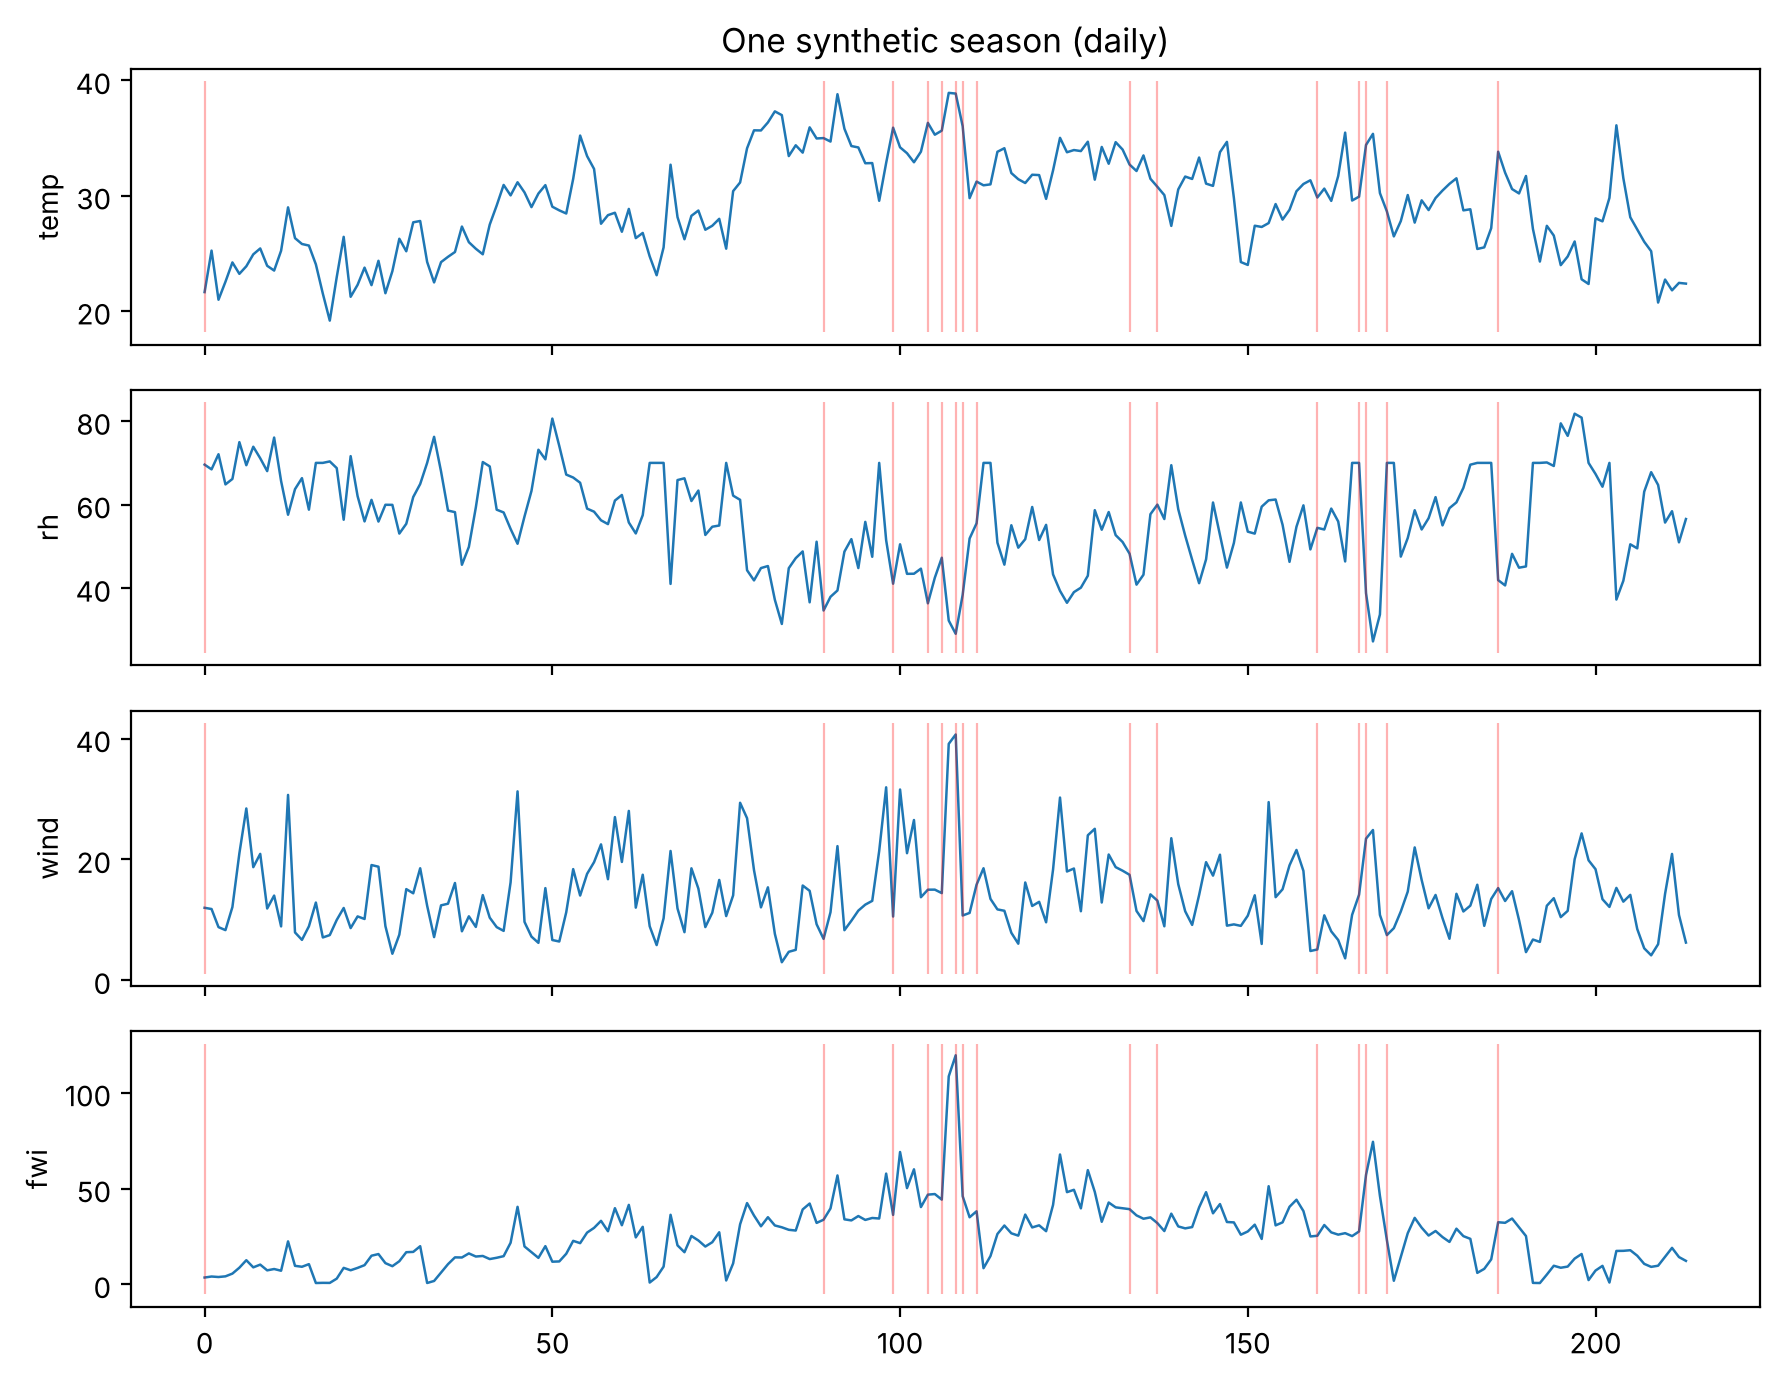

In [3]:
fig, ax = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
for a, k in zip(ax, ("temp", "rh", "wind", "fwi")):
    a.plot(t[k], lw=.9); a.set_ylabel(k)
ax[0].set_title("One synthetic season (daily)")
fire = np.where(t["fire"] > 0)[0]
for a in ax: a.vlines(fire, *a.get_ylim(), color="r", alpha=.3, lw=.8)
plt.tight_layout(); plt.show()

## 2. How the fire label is made (synthetic)
A latent moisture state (time constant τ = 4 days) is driven by temperature, humidity, rain, wind and a dry streak;
the hazard is a logistic function of it, with the intercept solved so that **6 % of days have a fire**. Because we
wrote the hazard, `p_true` (the true daily fire probability) is available: an oracle. Two variants:
- `additive` (S1): memory enters linearly — a logistic regression on today's values should do well.
- `interaction` (S2): heat-wave run × wind² — memory plus non-additivity, where a recurrent model *could* help.

In [4]:
X, Y, meta = features.build_windows(datasets.synthetic(n_years=30, seed=0))
print("windows:", X.shape, "labels:", Y.shape, "| positive rate per horizon:", Y.mean(0).round(3))
print("oracle AP upper bound is computed in notebook 02")

windows: (5430, 14, 12) labels: (5430, 3) | positive rate per horizon: [0.061 0.061 0.061]
oracle AP upper bound is computed in notebook 02


## 3. The real data (Algerian, evidence level A)
One row = one day: noon weather plus the published FFMC/DMC/DC/ISI/BUI/FWI and a *fire / not fire* class.
Two known quirks, both handled in code and logged: (i) a second header row in the middle of the file;
(ii) **one row (Bejaia, 14/07/2012) has an empty class** — the mirror we use counts 137 fire + 106 not fire + 1 unlabeled,
whereas UCI reports 138/106. We keep the day as NaN and drop every window whose label set touches it
(we do not guess the label).

In [5]:
alg = ROOT.parents[1] / "data/algerian/Algerian_forest_fires_dataset_UPDATE.csv"
tabs = datasets.algerian(alg)
for t in tabs:
    f = t["fire"]
    print(t["group"][0], "days:", len(f), "| fire:", int(np.nansum(f)), "| not fire:", int((f == 0).sum()), "| unlabeled:", int(np.isnan(f).sum()))

Bejaia days: 122 | fire: 59 | not fire: 63 | unlabeled: 0
SidiBelAbbes days: 122 | fire: 78 | not fire: 43 | unlabeled: 1


**Important limitation.** "Fire" here is a daily class assigned in a forest-fire study, in a region with a different climate
from Tunisia's. Roughly half the days are fires, against a few percent in reality. This is a *sanity check on real weather
dynamics*, not an estimate of field performance.

In [6]:
Xa, Ya, ma = features.build_windows(tabs)
print("Algerian windows:", Xa.shape, "positives h=1:", int(Ya[:, 0].sum()), "of", len(Ya))

Algerian windows: (174, 14, 12) positives h=1: 109 of 174


## 4. Leakage rules we apply
1. Windows are formed inside a season, never across seasons/sites.
2. Train / validation / test are split **by whole season (synthetic) or whole site (Algerian)**.
3. Standardisation and calibration are fitted on training / validation only.
4. Confidence intervals use a **block bootstrap** (blocks = consecutive days of one season), because neighbouring days are correlated.